# 04 Exploratory analysis and maps

Pictures of what notebooks 02 and 03 found, made to be read without the tables: where exposure is highest, how it changed, when in the year it peaks, and how it is spread across people. Every figure is saved to `outputs/figures/` for the report and dashboard.

**Figures**
1. The 1 km PM2.5 surface: latest five years and change since the first five
2. Upazila maps: latest five-year mean and change
3. Division trends, 1998 to 2024, with 2018 marked
4. Month by year heatmap for the whole country
5. Month by division heatmap
6. How exposure is spread across people, first year vs last year
7. Where population weighting matters, and why
8. Dry season vs monsoon, indexed to their own starting level

**Reading note on 2018:** in this release (V6.GL.03) 2018 sits about 28% above the years around it, while the previous release shows only about 3%. Notebook 03 (q11) showed it moves the national linear trend by about 7%. It is kept and marked on the time-series figures, and the five-year means used for the maps soften it.

**Inputs:** `data/processed/` (bgd_admin.gpkg, pm25_annual_grid.nc, pm25_unit_year, pm25_unit_month, pm25_who_bands)

In [1]:
%pip install -q rioxarray

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 3.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 28.7 MB/s eta 0:00:00


In [2]:
import pandas as pd, numpy as np, xarray as xr, geopandas as gpd, rioxarray, pathlib
import matplotlib.pyplot as plt, matplotlib.colors as mcolors

try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = pathlib.Path("/content/drive/MyDrive/Bangladesh Air Pollution Project")
except ImportError:
    ROOT = pathlib.Path.cwd().parent

PROC, FIG, TAB = ROOT / "data" / "processed", ROOT / "outputs" / "figures", ROOT / "outputs" / "tables"
for d in (FIG, TAB):
    d.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
PLUM, CMAP = "#6b2d5c", "magma_r"

division, district, upazila = (gpd.read_file(PROC / "bgd_admin.gpkg", layer=l) for l in ("division", "district", "upazila"))
country = division.dissolve()
uy = pd.read_parquet(PROC / "pm25_unit_year.parquet")
um = pd.read_parquet(PROC / "pm25_unit_month.parquet").assign(year=lambda d: d["date"].dt.year, month=lambda d: d["date"].dt.month)
grid = xr.open_dataset(PROC / "pm25_annual_grid.nc").load()
YEARS = sorted(uy["year"].unique())
FIRST, LAST = YEARS[:5], YEARS[-5:]
period = lambda df, yrs: df[df["year"].isin(yrs)].groupby(["level", "pcode", "name"], as_index=False)["pm25_popw"].mean()
print(f"{YEARS[0]} to {YEARS[-1]} | first period {FIRST[0]}-{FIRST[-1]}, last period {LAST[0]}-{LAST[-1]}")

Mounted at /content/drive
1998 to 2024 | first period 1998-2002, last period 2020-2024


## 1. The 1 km surface

The raw 0.01° grid, clipped to the border: the mean of the last five years and the change from the first five. This is the most detailed view in the project and shows patterns that district averages hide, such as the plume along the Dhaka to Narayanganj corridor and the cleaner air over the Sundarbans and the Chittagong Hill Tracts.

1 km cells: recent mean 61.9, range 28.3 to 89.9; change -4.0 to +41.6 ug/m3


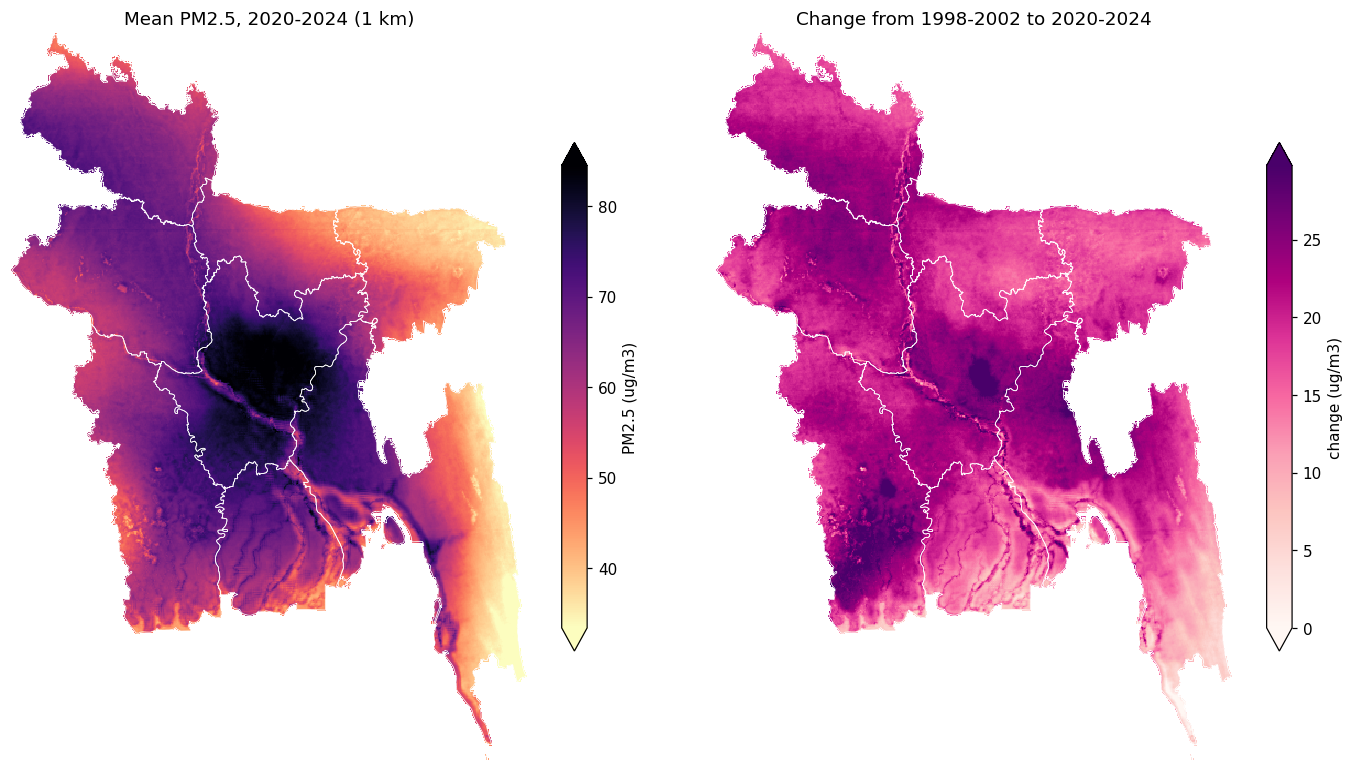

In [3]:
pm = grid["pm25"].rio.write_crs(4326).rio.set_spatial_dims("lon", "lat").rio.clip(country.geometry, all_touched=True, drop=True)
recent, change = pm.sel(year=LAST).mean("year"), pm.sel(year=LAST).mean("year") - pm.sel(year=FIRST).mean("year")
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
recent.plot(ax=ax[0], cmap=CMAP, vmin=float(recent.quantile(0.01)), vmax=float(recent.quantile(0.99)), cbar_kwargs={"label": "PM2.5 (ug/m3)", "shrink": 0.7})
change.plot(ax=ax[1], cmap="RdPu", vmin=0, vmax=float(change.quantile(0.99)), cbar_kwargs={"label": "change (ug/m3)", "shrink": 0.7})
for a, t in zip(ax, (f"Mean PM2.5, {LAST[0]}-{LAST[-1]} (1 km)", f"Change from {FIRST[0]}-{FIRST[-1]} to {LAST[0]}-{LAST[-1]}")):
    division.boundary.plot(ax=a, color="white", linewidth=0.5); a.set_title(t); a.set_axis_off()
plt.tight_layout(); plt.savefig(FIG / "04_surface_recent_change.png", dpi=200, bbox_inches="tight")
print(f"1 km cells: recent mean {float(recent.mean()):.1f}, range {float(recent.min()):.1f} to {float(recent.max()):.1f}; change {float(change.min()):+.1f} to {float(change.max()):+.1f} ug/m3")

## 2. Upazila maps

The same two views at upazila level, population-weighted, which is what the dashboard and the hotspot analysis use. The five highest upazilas in the last period are labelled.

,count,mean,std,min,25%,50%,75%,max
recent,507.0,64.8,11.1,33.6,59.5,66.8,71.8,85.3
change,507.0,20.7,4.2,1.8,18.0,21.0,23.6,34.7


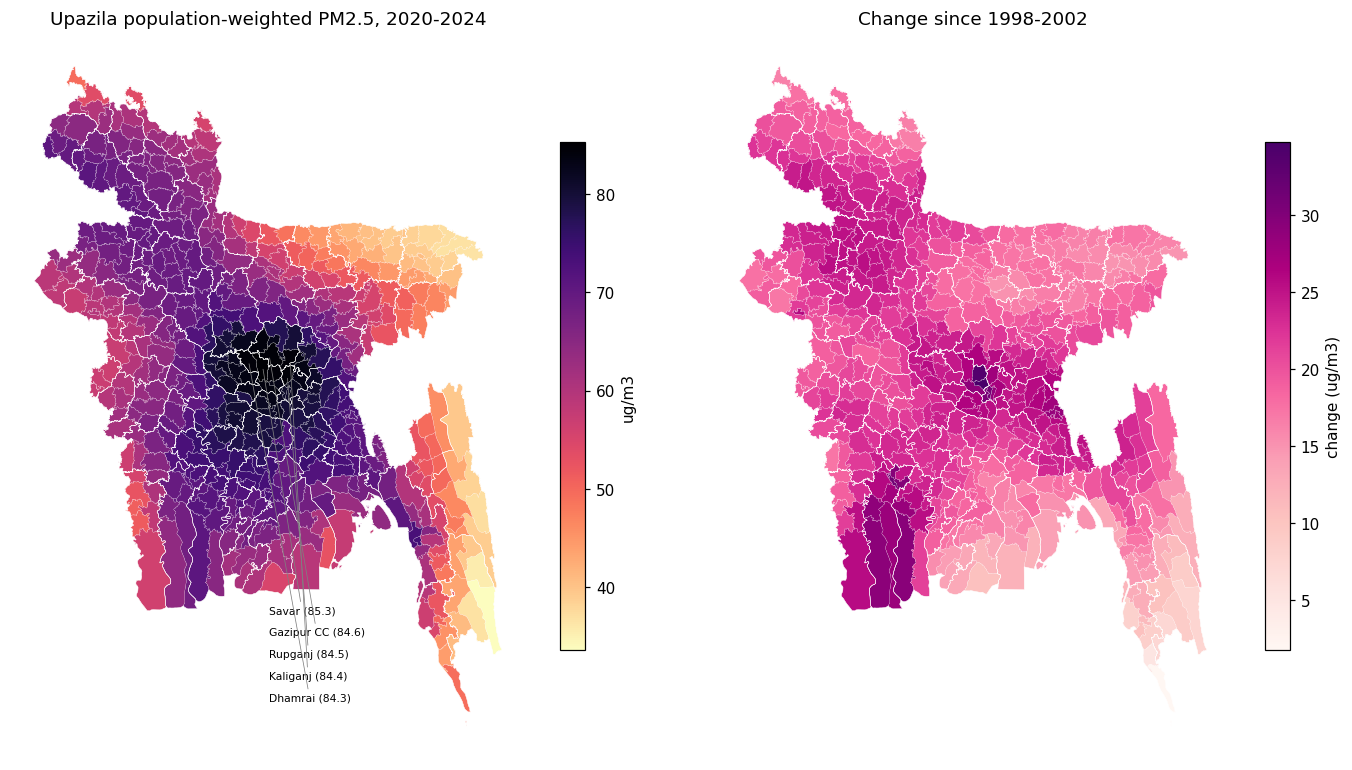

In [4]:
u = upazila.merge(period(uy.query("level == 'upazila'"), LAST)[["pcode", "pm25_popw"]].rename(columns={"pm25_popw": "recent"})).merge(
    period(uy.query("level == 'upazila'"), FIRST)[["pcode", "pm25_popw"]].rename(columns={"pm25_popw": "early"})).assign(change=lambda d: d["recent"] - d["early"])
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
u.plot(column="recent", ax=ax[0], cmap=CMAP, legend=True, legend_kwds={"label": "ug/m3", "shrink": 0.7}, edgecolor="white", linewidth=0.1)
u.plot(column="change", ax=ax[1], cmap="RdPu", legend=True, legend_kwds={"label": "change (ug/m3)", "shrink": 0.7}, edgecolor="white", linewidth=0.1)
for k, (_, r) in enumerate(u.nlargest(5, "recent").iterrows()):
    ax[0].annotate(f'{r["name"].replace(" City Corporation", " CC")} ({r["recent"]:.1f})', r.geometry.representative_point().coords[0], xytext=(90.35, 21.65 - k * 0.2), textcoords="data", fontsize=7, va="center", bbox={"fc": "white", "ec": "none", "alpha": 0.8, "pad": 0.5}, arrowprops={"arrowstyle": "-", "lw": 0.5, "color": "grey"})
for a, t in zip(ax, (f"Upazila population-weighted PM2.5, {LAST[0]}-{LAST[-1]}", f"Change since {FIRST[0]}-{FIRST[-1]}")):
    district.boundary.plot(ax=a, color="white", linewidth=0.3); a.set_title(t); a.set_axis_off()
plt.tight_layout(); plt.savefig(FIG / "04_upazila_recent_change.png", dpi=200, bbox_inches="tight")
u[["name", "recent", "change"]].describe().round(1).T

## 3. Division trends

Every division's population-weighted mean by year, with the country in bold. The order of divisions hardly changes over 27 years (q04 found no rank changes between the first and last five years), so the story is a shared rise, not one region catching up.

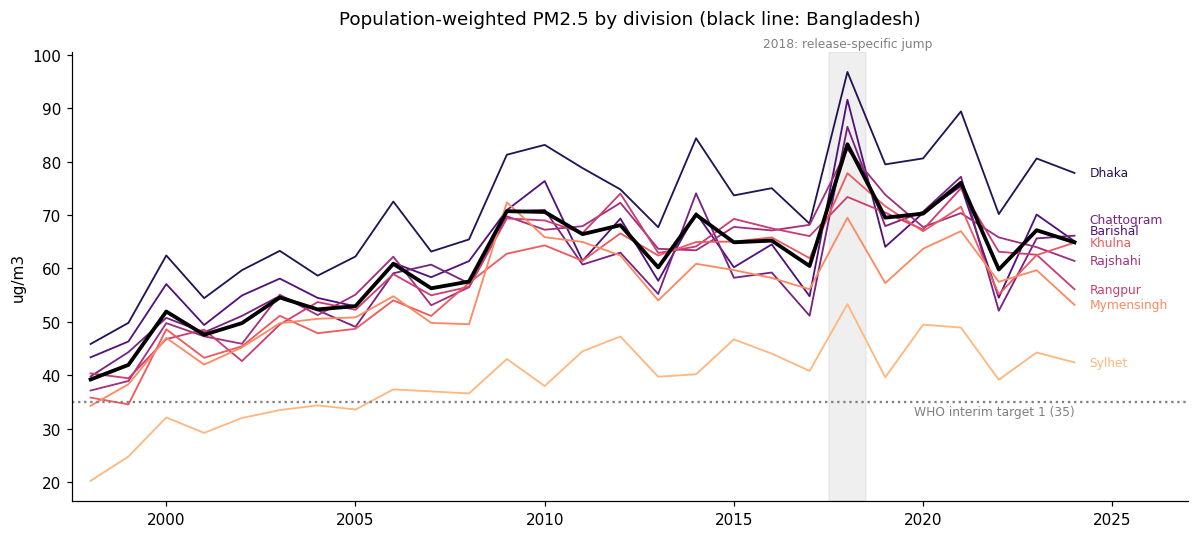

In [5]:
dv = uy.query("level == 'division'").pivot(index="year", columns="name", values="pm25_popw")
nat = uy.query("level == 'national'").set_index("year")["pm25_popw"]
fig, ax = plt.subplots(figsize=(11, 5))
order = dv.loc[LAST].mean().sort_values(ascending=False).index
colors = plt.cm.magma(np.linspace(0.15, 0.85, len(order)))
ends = dv.iloc[-1][order].sort_values()
label_y = np.maximum.accumulate(ends.values - np.arange(len(ends)) * 2.2) + np.arange(len(ends)) * 2.2
for c, name in zip(colors, order):
    ax.plot(dv.index, dv[name], color=c, lw=1.2)
    ax.text(YEARS[-1] + 0.4, label_y[list(ends.index).index(name)], name, fontsize=8, va="center", color=c)
ax.plot(nat.index, nat, color="black", lw=2.5)
ax.axvspan(2017.5, 2018.5, color="grey", alpha=0.12); ax.text(2018, 1.01, "2018: release-specific jump", ha="center", fontsize=8, color="grey", transform=ax.get_xaxis_transform())
ax.axhline(35, ls=":", color="grey"); ax.text(YEARS[-1], 32.5, "WHO interim target 1 (35)", fontsize=8, color="grey", ha="right")
ax.set(ylabel="ug/m3", xlim=(YEARS[0] - 0.5, YEARS[-1] + 3)); ax.set_title("Population-weighted PM2.5 by division (black line: Bangladesh)", pad=18)
plt.tight_layout(); plt.savefig(FIG / "04_division_trends.png", dpi=200, bbox_inches="tight")

## 4. Month by year heatmap

Each row is a year and each column a month, for the national population-weighted mean. It shows the seasonal cycle and the long-term rise in one picture: the dry season (November to March) darkens over time, and the monsoon months, while still the cleanest, get steadily less clean.

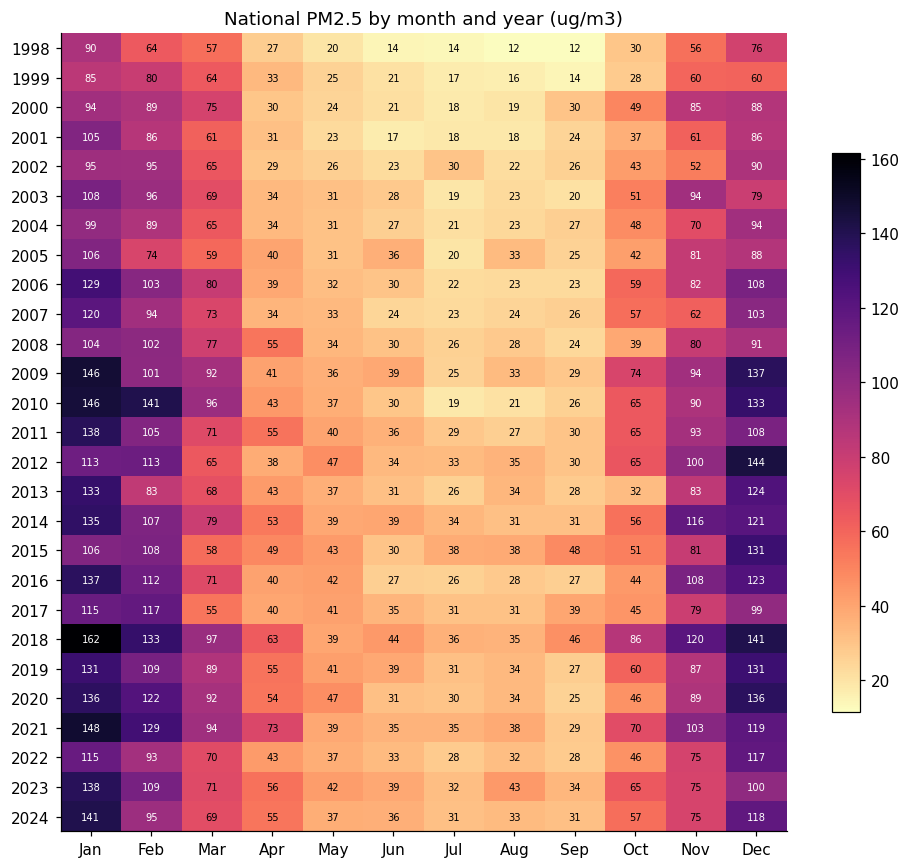

In [6]:
nm = um.query("level == 'national'").pivot(index="year", columns="month", values="pm25_popw")
fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(nm, aspect="auto", cmap=CMAP)
ax.set(xticks=range(12), xticklabels=[pd.Timestamp(2000, m, 1).strftime("%b") for m in nm.columns], yticks=range(len(nm)), yticklabels=nm.index, title="National PM2.5 by month and year (ug/m3)")
for (i, j), v in np.ndenumerate(nm.values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > nm.values.mean() + 20 else "black")
plt.colorbar(im, ax=ax, shrink=0.7); plt.tight_layout(); plt.savefig(FIG / "04_month_year_heatmap.png", dpi=200, bbox_inches="tight")

## 5. Month by division

The average seasonal profile of each division over all years. Most divisions peak in January and are cleanest in July; Barishal and Chattogram, on the coast, behave a little differently (q09).

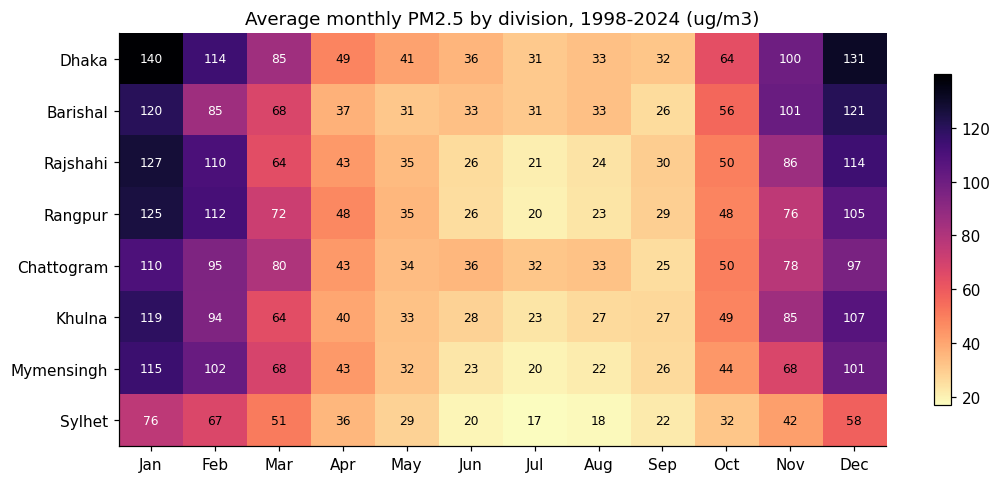

In [7]:
dm = um.query("level == 'division'").groupby(["name", "month"])["pm25_popw"].mean().unstack()
dm = dm.loc[dm.mean(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(10, 4.5))
im = ax.imshow(dm, aspect="auto", cmap=CMAP)
ax.set(xticks=range(12), xticklabels=[pd.Timestamp(2000, m, 1).strftime("%b") for m in dm.columns], yticks=range(len(dm)), yticklabels=dm.index, title=f"Average monthly PM2.5 by division, {YEARS[0]}-{YEARS[-1]} (ug/m3)")
for (i, j), v in np.ndenumerate(dm.values):
    ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 70 else "black")
plt.colorbar(im, ax=ax, shrink=0.8); plt.tight_layout(); plt.savefig(FIG / "04_month_division_heatmap.png", dpi=200, bbox_inches="tight")

## 6. How exposure is spread across people

A population-weighted distribution: each 1 km cell counts as many times as the people living in it. This answers "what share of people breathe what level", which a map cannot show. The WHO interim target 1 (35 µg/m³) is marked.

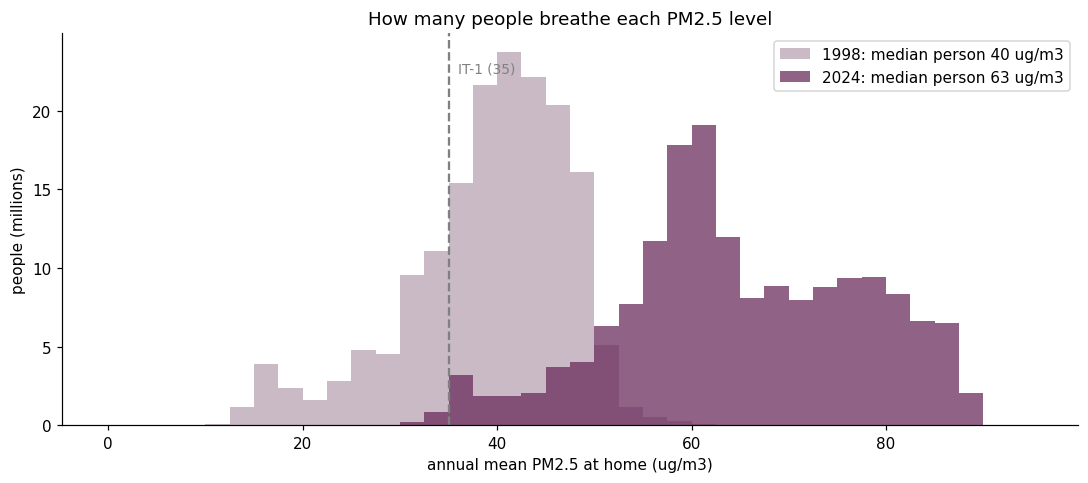

In [8]:
w = grid["pop_2022"].values.ravel()
wmedian = lambda v, wt: v[np.argsort(v)][np.searchsorted(np.cumsum(wt[np.argsort(v)]), wt.sum() / 2)]
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(0, float(grid["pm25"].sel(year=[YEARS[0], YEARS[-1]]).max()) + 5, 2.5)
for y, c in ((YEARS[0], "#b8a3b3"), (YEARS[-1], PLUM)):
    v = grid["pm25"].sel(year=y).values.ravel(); ok = (w > 0) & ~np.isnan(v)
    ax.hist(v[ok], bins=bins, weights=w[ok] / 1e6, color=c, alpha=0.75, label=f"{y}: median person {wmedian(v[ok], w[ok]):.0f} ug/m3")
ax.axvline(35, ls="--", color="grey"); ax.text(36, ax.get_ylim()[1] * 0.9, "IT-1 (35)", color="grey", fontsize=9)
ax.set(title="How many people breathe each PM2.5 level", xlabel="annual mean PM2.5 at home (ug/m3)", ylabel="people (millions)"); ax.legend()
plt.tight_layout(); plt.savefig(FIG / "04_exposure_distribution.png", dpi=200, bbox_inches="tight")

## 7. Where population weighting matters, and why

Each point is a district: its simple area mean against its population-weighted mean over the last five years. Points above the line mean residents breathe more than the map average suggests.

Correction to the note in notebook 03 (q12): the biggest gaps are not in the densest, most urban districts. They are in Bagerhat, Khulna, Bhola and the Hill Tracts, where large stretches of cleaner, nearly empty land (the Sundarbans, rivers, hill forest) pull the area mean down while people live in the more polluted parts. In dense districts like Dhaka almost every cell is populated, so the two means are nearly the same.

Spearman correlation between density and gap: 0.02


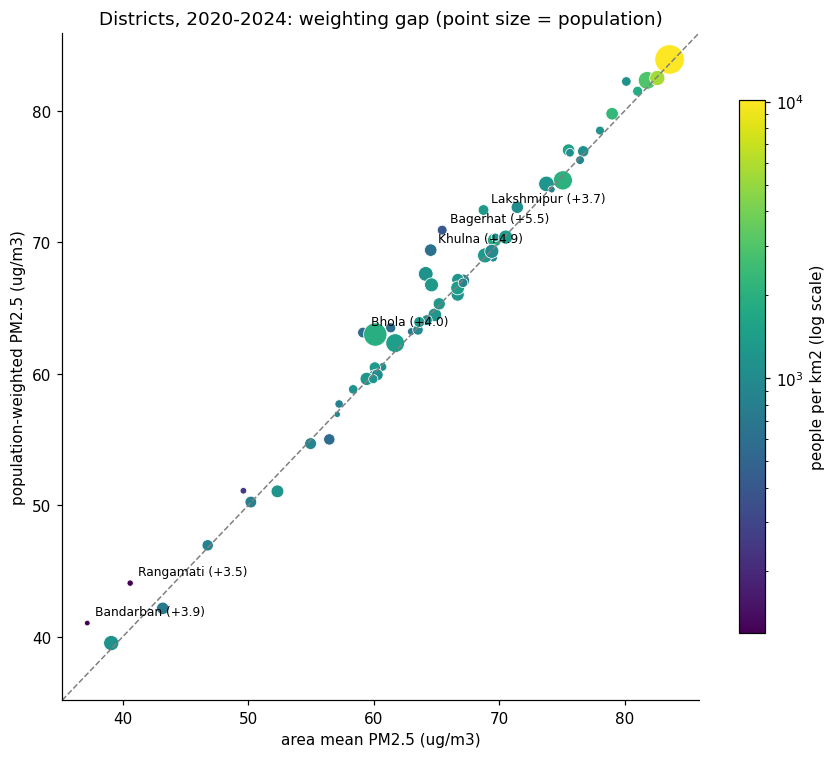

In [9]:
dd = district.merge(period(uy.query("level == 'district'"), LAST)[["pcode", "pm25_popw"]]).merge(
    uy[uy["year"].isin(LAST) & (uy["level"] == "district")].groupby("pcode", as_index=False).agg(pm25_area=("pm25_area", "mean"), pop=("pop", "max")))
dd = dd.assign(density=dd["pop"] / dd["area_km2"], gap=dd["pm25_popw"] - dd["pm25_area"])
fig, ax = plt.subplots(figsize=(8, 7))
sc = ax.scatter(dd["pm25_area"], dd["pm25_popw"], s=dd["pop"] / 4e4, c=dd["density"], cmap="viridis", norm=mcolors.LogNorm(), edgecolor="white", lw=0.5)
lim = [dd[["pm25_area", "pm25_popw"]].min().min() - 2, dd[["pm25_area", "pm25_popw"]].max().max() + 2]
ax.plot(lim, lim, color="grey", ls="--", lw=1)
for _, r in dd.nlargest(6, "gap").iterrows():
    ax.annotate(f"{r['name']} (+{r['gap']:.1f})", (r["pm25_area"], r["pm25_popw"]), xytext=(5, 5), textcoords="offset points", fontsize=8)
plt.colorbar(sc, ax=ax, label="people per km2 (log scale)", shrink=0.8)
ax.set(xlim=lim, ylim=lim, xlabel="area mean PM2.5 (ug/m3)", ylabel="population-weighted PM2.5 (ug/m3)", title=f"Districts, {LAST[0]}-{LAST[-1]}: weighting gap (point size = population)")
plt.tight_layout(); plt.savefig(FIG / "04_weighting_gap.png", dpi=200, bbox_inches="tight")
print(f"Spearman correlation between density and gap: {dd[['density', 'gap']].corr('spearman').iloc[0, 1]:.2f}")

## 8. Dry season vs monsoon

q10 found the dry season rising faster in absolute terms (µg/m³ per year). Indexing each season to its own first five years shows the relative change: the monsoon, starting from a much cleaner level, has worsened proportionally more. Clean months are disappearing, not just bad months getting worse.

,"last 5 seasons, index"
season,
dry (Dec-Feb),141.0
monsoon (Jun-Aug),182.0


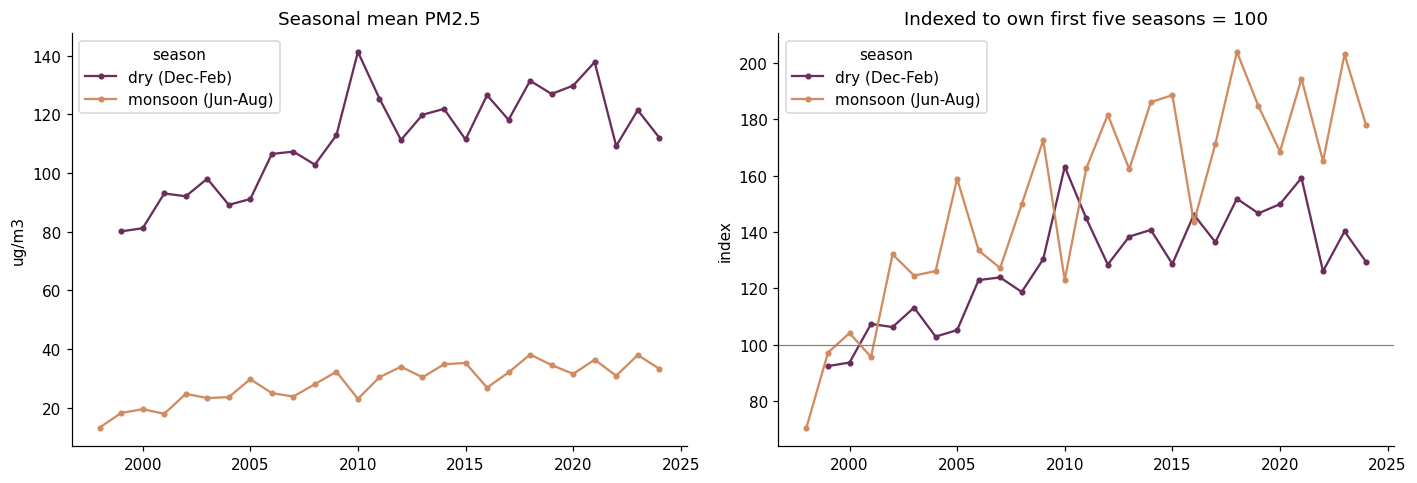

In [10]:
s = um.query("level == 'national' and month in [12, 1, 2, 6, 7, 8]").assign(season=lambda d: np.where(d["month"].isin([12, 1, 2]), "dry (Dec-Feb)", "monsoon (Jun-Aug)"),
    season_year=lambda d: np.where(d["month"] == 12, d["year"] + 1, d["year"]))
s = s.groupby(["season", "season_year"]).filter(lambda g: len(g) == 3).groupby(["season", "season_year"])["pm25_popw"].mean().unstack(0)
idx = s / s.iloc[:5].mean() * 100
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
s.plot(ax=ax[0], marker="o", ms=3, color=[PLUM, "#d08c60"]); ax[0].set(title="Seasonal mean PM2.5", ylabel="ug/m3", xlabel="")
idx.plot(ax=ax[1], marker="o", ms=3, color=[PLUM, "#d08c60"]); ax[1].axhline(100, color="grey", lw=0.8)
ax[1].set(title="Indexed to own first five seasons = 100", ylabel="index", xlabel="")
plt.tight_layout(); plt.savefig(FIG / "04_dry_vs_monsoon.png", dpi=200, bbox_inches="tight")
idx.iloc[-5:].mean().round(0).rename("last 5 seasons, index")

## Key numbers

The figures most likely to be quoted in the report, the README and LinkedIn, computed in one place so every document uses the same values.

In [11]:
wb = pd.read_parquet(PROC / "pm25_who_bands.parquet").query("level == 'national'")
e, r = nat.loc[FIRST].mean(), nat.loc[LAST].mean()
above35 = wb[(wb["year"] == YEARS[-1]) & (wb["band"] == ">35 above IT-1")]["share"].iloc[0] * 100
dlast, ulast = period(uy.query("level == 'district'"), LAST), period(uy.query("level == 'upazila'"), LAST)
key = pd.DataFrame([
    ("National population-weighted PM2.5, first five years", f"{e:.1f} ug/m3"),
    ("National population-weighted PM2.5, last five years", f"{r:.1f} ug/m3"),
    ("Change between the periods", f"+{r - e:.1f} ug/m3 ({(r / e - 1) * 100:.0f}%)"),
    ("Times the WHO guideline (5), last five years", f"{r / 5:.1f}x"),
    (f"People above 35 ug/m3 in {YEARS[-1]}", f"{above35:.1f}%"),
    ("Worst district, last five years", f"{dlast.nlargest(1, 'pm25_popw')['name'].iloc[0]} ({dlast['pm25_popw'].max():.1f})"),
    ("Cleanest district, last five years", f"{dlast.nsmallest(1, 'pm25_popw')['name'].iloc[0]} ({dlast['pm25_popw'].min():.1f})"),
    ("Worst upazila, last five years", f"{ulast.nlargest(1, 'pm25_popw')['name'].iloc[0]} ({ulast['pm25_popw'].max():.1f})"),
    ("Worst month (national average)", f"{pd.Timestamp(2000, int(nm.mean().idxmax()), 1):%B} ({nm.mean().max():.0f})"),
    ("Cleanest month (national average)", f"{pd.Timestamp(2000, int(nm.mean().idxmin()), 1):%B} ({nm.mean().min():.0f})"),
], columns=["measure", "value"])
key.to_csv(TAB / "04_key_numbers.csv", index=False)
key

,measure,value
0,"National population-weighted PM2.5, first five...",46.1 ug/m3
1,"National population-weighted PM2.5, last five ...",67.6 ug/m3
2,Change between the periods,+21.6 ug/m3 (47%)
3,"Times the WHO guideline (5), last five years",13.5x
4,People above 35 ug/m3 in 2024,99.4%
5,"Worst district, last five years",Dhaka (83.9)
6,"Cleanest district, last five years",Sylhet (39.5)
7,"Worst upazila, last five years",Savar (85.3)
8,Worst month (national average),January (121)
9,Cleanest month (national average),July (26)


## Next: notebook 05, machine learning on drivers

Which area characteristics go with higher PM2.5 (population density, urban share, distance to Dhaka, roads, elevation, dry-season wind and rain), tested with random forest and XGBoost under random and spatial cross-validation, with SHAP to explain the model.